# Causal mediation: how much of an effect runs through a mediator?

A training programme raises earnings. Is that because participants work more hours, or because they
earn more per hour? Mediation analysis splits the total effect of a treatment $D$ into an
**indirect** effect, which runs through a mediator $M$ (hours worked), and a **direct** effect, which
runs through everything else. Both are defined by potential outcomes $Y(d, M(d'))$: the outcome under
treatment $d$ when the mediator takes the value it would take under treatment $d'$.

| effect | definition |
|---|---|
| total | $E[Y(1, M(1))] - E[Y(0, M(0))]$ |
| direct (treated / control) | $E[Y(1, M(d))] - E[Y(0, M(d))]$ for $d = 1$ / $0$ |
| indirect (treated / control) | $E[Y(d, M(1))] - E[Y(d, M(0))]$ for $d = 1$ / $0$ |

The two versions of each effect differ when the treatment and the mediator interact. Identification
requires that the covariates $X$ contain all confounders of the treatment, the mediator and the
outcome, and that none of them is affected by the treatment. `dml_rs.Mediation` is the double
machine learning estimator of Farbmacher, Huber, Lafférs, Langen and Spindler (2022), the estimator
of R's `causalweight::medDML`, and reproduces it to `1e-9`.

This notebook uses simulated data, so the true effects are known.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

import dml_rs

pd.set_option("display.precision", 3)


def simulate(n, rng):
    # Training D, weekly hours M and earnings Y, confounded by X.
    # Also returns the potential-outcome means E[Y(d, M(d'))].
    X = rng.normal(size=(n, 5))
    e = 1 / (
        1
        + np.exp(
            -(0.8 * X[:, 0] - 0.6 * X[:, 1] + 0.4 * X[:, 0] * X[:, 2])
        )
    )
    D = (rng.random(n) < e).astype(float)
    u_m, u_y = rng.normal(size=n), rng.normal(size=n)

    def hours(d):
        return (
            2
            + 1.0 * d
            + 0.8 * np.tanh(X[:, 0])
            + 0.5 * X[:, 1] ** 2
            + u_m
        )

    def earnings(
        d, m
    ):  # training raises the return to each hour: a D × M interaction
        return (
            1
            + 0.5 * d
            + (1 + 0.5 * d) * m
            + np.exp(X[:, 0] / 2)
            + 0.5 * X[:, 1] * X[:, 2]
            + u_y
        )

    M = hours(D)
    potential = {
        (d, dp): earnings(d, hours(dp)).mean()
        for d in (0, 1)
        for dp in (0, 1)
    }
    return X, D, M, earnings(D, M), potential


_, _, _, _, po = simulate(
    2_000_000, np.random.default_rng(1)
)  # a large sample for the true effects
truth = pd.Series(
    {
        "total": po[1, 1] - po[0, 0],
        "direct (treated)": po[1, 1] - po[0, 1],
        "direct (control)": po[1, 0] - po[0, 0],
        "indirect (treated)": po[1, 1] - po[1, 0],
        "indirect (control)": po[0, 1] - po[0, 0],
    },
    name="truth",
)

X, D, M, Y, _ = simulate(5000, np.random.default_rng(2))
truth

total                 3.25
direct (treated)      2.25
direct (control)      1.75
indirect (treated)    1.50
indirect (control)    1.00
Name: truth, dtype: float64

Training adds one hour per week, and each hour earns 1 without training and 1.5 with it. So the
indirect effect is 1.5 for the treated and 1.0 for the controls. The direct effect is 0.5 plus the
extra return on the hours a unit would work anyway.

## Naive approaches

The difference in mean earnings mixes the effect with confounding. A linear regression of $Y$ on $D$,
$M$ and $X$, the classic Baron–Kenny approach, gives a "direct effect". However, it assumes linear
confounding and no interaction, and it misses both here.

In [2]:
pd.Series(
    {
        "difference in means (total)": Y[D == 1].mean()
        - Y[D == 0].mean(),
        "OLS coefficient of D given M, X (direct)": LinearRegression()
        .fit(np.column_stack([D, M, X]), Y)
        .coef_[0],
    }
)

difference in means (total)                 4.034
OLS coefficient of D given M, X (direct)    2.040
dtype: float64

## Double machine learning

`Mediation` takes a regressor for the outcome means $E[Y \mid D, X]$ and $E[Y \mid D, M, X]$ and a
classifier for the propensity scores $P(D = 1 \mid X)$ and $P(D = 1 \mid M, X)$. The scores reweight
by these two propensities instead of estimating the mediator's density, so the mediator can be
continuous, binary or several variables. The nested means $E[E[Y \mid D = d, M, X] \mid D = 1 - d, X]$
are fitted on a separate part of each training sample and debiased (Qi and Zhang, 2026).

In [3]:
def forests():
    return (
        dml_rs.RandomForestRegressor(
            n_estimators=200, min_samples_leaf=5
        ),
        dml_rs.RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5
        ),
    )


med = dml_rs.Mediation(*forests()).fit(X, Y, D, M)
med.summary[["coef", "std err", "2.5 %", "97.5 %"]].join(truth)

,coef,std err,2.5 %,97.5 %,truth
total,3.253,0.058,3.138,3.367,3.25
direct (treated),2.286,0.055,2.177,2.394,2.25
direct (control),1.821,0.051,1.721,1.922,1.75
indirect (treated),1.432,0.063,1.309,1.554,1.50
indirect (control),0.967,0.052,0.864,1.070,1.00


All five effects are close to the truth, with standard errors of about 0.05. About 44% of the total
effect of training runs through hours worked (46% in the truth):

In [4]:
print(
    f"indirect (treated) / total = {med.coef_[3] / med.coef_[0]:.2f}",
    f"(truth {truth.iloc[3] / truth.iloc[0]:.2f})"
)

indirect (treated) / total = 0.44 (truth 0.46)


`potential_outcomes()` returns the four means $E[Y(d, M(d'))]$ themselves as a `Framework`, so any
other contrast is a linear combination of them:

In [5]:
pd.concat(
    [
        med.potential_outcomes().summary[["coef", "std err"]],
        pd.Series(
            {
                f"Y({d}, M({dp}))": po[d, dp]
                for d in (1, 0)
                for dp in (1, 0)
            },
            name="truth",
        ),
    ],
    axis=1,
)

,coef,std err,truth
"Y(1, M(1))",7.873,0.050,7.883
"Y(1, M(0))",6.442,0.062,6.383
"Y(0, M(1))",5.588,0.057,5.633
"Y(0, M(0))",4.621,0.042,4.633


## Overlap and trimming

The mediator carries information about the treatment: treated units work more hours. So
$P(D = 1 \mid M, X)$ is more extreme than $P(D = 1 \mid X)$, and the weights that involve it are
larger. Check the overlap of both propensity scores:

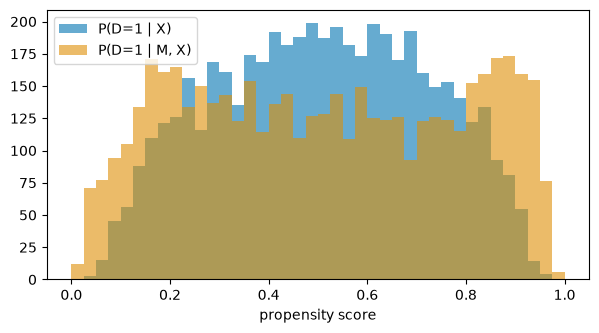

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(
    med.predictions_["ml_m"].ravel(),
    bins=bins,
    alpha=0.6,
    color="#0173B2",
    label="P(D=1 | X)",
)
ax.hist(
    med.predictions_["ml_m_mediator"].ravel(),
    bins=bins,
    alpha=0.6,
    color="#DE8F05",
    label="P(D=1 | M, X)",
)
ax.set_xlabel("propensity score")
ax.legend();

`medDML` drops observations with small propensities (`trimming_rule="drop"`, threshold 0.05).
`P(D = 1 | M, X)` depends on the mediator, an outcome of the treatment. So dropping on it selects on a
post-treatment variable, and the remaining units no longer represent the population. dml-rs clips the
propensities instead (`trimming_rule="truncate"`, the default). With `"drop"`, the total and indirect
effects move away from the truth by several standard errors:

In [7]:
drop = dml_rs.Mediation(
    *forests(), trimming_rule="drop", trimming_threshold=0.05
).fit(X, Y, D, M)
print("observations dropped:", drop.n_trimmed_[0])
pd.DataFrame(
    {
        "truncate (default)": med.coef_,
        "drop (medDML)": drop.coef_,
        "truth": truth.to_numpy(),
    },
    index=truth.index,
)

observations dropped: 341


,truncate (default),drop (medDML),truth
total,3.253,3.134,3.25
direct (treated),2.286,2.254,2.25
direct (control),1.821,1.805,1.75
indirect (treated),1.432,1.329,1.50
indirect (control),0.967,0.879,1.00


The choice of learners matters for the same reason. Learners that push propensities to 0 or 1 make
some weights large and the standard errors of the effects that use them wide. Compare the standard
errors with gradient boosting:

In [8]:
boost = dml_rs.Mediation(
    dml_rs.HistGradientBoostingRegressor(),
    dml_rs.HistGradientBoostingClassifier(),
).fit(X, Y, D, M)
pd.DataFrame(
    {"forest se": med.se_, "boosting se": boost.se_}, index=truth.index
)

,forest se,boosting se
total,0.058,0.072
direct (treated),0.055,0.450
direct (control),0.051,0.110
indirect (treated),0.063,0.118
indirect (control),0.052,0.453


Use `n_rep > 1` to average over several sample splits, and compare learners by their nuisance losses
(`evaluate_learners`) before reading the effects.

## Summary

- `Mediation` estimates the total, natural direct and natural indirect effects of a binary treatment
  for one or several mediators of any type. The data role is `m` (`DmlData(..., m_cols=...)`).
- The effects need all confounders of the treatment, the mediator and the outcome in $X$. A
  randomised treatment does not make the mediator's effect unconfounded.
- Inspect the overlap of $P(D = 1 \mid M, X)$. Keep the default truncation: dropping units on this
  post-treatment propensity biases the effects.